# Monte Carlo Integration


| Date | Who | Mail |  What |
| ---  | --- | ---  | ---   |     
| Nov 25, 2026 | Diego Andrés Alvarez Marín | <daalvarez@unal.edu.co>  | Initial code created using Gemini Neon      |
| Nov 25, 2026 | Diego Andrés Alvarez Marín | <daalvarez@unal.edu.co>  | Code, formulation and comments improvements |

This notebook provides a hands-on tutorial on **Monte Carlo Integration**.

### What You Will Learn
1. **Theoretical Framework & Nomenclature**: Reformulating deterministic integrals as expectations $I = \mathbb{E}[g(\boldsymbol{X})]$ and estimating them via the sample mean $\hat{I}_N$.
2. **Unidimensional Integration ($d = 1$)**: Estimating a 1D integral and comparing the Monte Carlo estimate $\hat{I}_N$ against the exact analytical and numerical quadrature results.
3. **Multidimensional Integration on a Circular Region ($d = 2$)**: Integrating over a 2D disk using two sampling strategies—bounding-box indicator sampling and direct uniform disk sampling via inverse transform sampling.
4. **Probabilistic Error Bounds as $N$ Increases**: Tracking convergence at the $O(N^{-1/2})$ rate, comparing **exact theoretical bounds** $c\,\sigma(g)/\sqrt{N}$ against **practical estimated bounds** $c s_N/\sqrt{N}$, and empirically validating the Central Limit Theorem (CLT) coverage probabilities.

## 1. Theoretical Framework & Nomenclature

### Solving an Integral via Monte Carlo Simulation
To estimate the $d$-dimensional integral
$$I = \int_{\mathbb{R}^d} g(\boldsymbol{x}) f_{\boldsymbol{X}}(\boldsymbol{x}) \, d\boldsymbol{x}$$
where $g: \mathbb{R}^d \to \mathbb{R}$ is a real-valued function and $f_{\boldsymbol{X}}(\boldsymbol{x})$ is a valid probability density function (PDF), we proceed in three steps:

1. **Reformulate as an Expected Value**:
   $$I = \mathbb{E}[g(\boldsymbol{X})]$$
   where $\boldsymbol{X}$ is a $d$-dimensional random vector distributed according to $f_{\boldsymbol{X}}(\boldsymbol{x})$.
2. **Generate Independent Random Samples**: Draw $N$ i.i.d. random vectors $\boldsymbol{x}_1, \boldsymbol{x}_2, \dots, \boldsymbol{x}_N \sim f_{\boldsymbol{X}}(\boldsymbol{x})$.
3. **Compute the Sample Mean**:
   $$\hat{I}_N = \frac{1}{N} \sum_{n=1}^{N} g(\boldsymbol{x}_n)$$
   By the **Strong Law of Large Numbers**, $\lim_{N \to \infty} \hat{I}_N = I$ with probability $1$.

### Probabilistic Error Bounds
Assuming $g(\boldsymbol{X})$ is square-integrable with finite variance $\sigma^2(g) = \mathbb{E}\left[(g(\boldsymbol{X}) - I)^2\right] < \infty$:

- **Mean-Square Error & Average Error (RMSE)**:
  $$\mathbb{E}\left[(\hat{I}_N - I)^2\right] = \frac{\sigma^2(g)}{N}, \qquad \text{Average Error} = \frac{\sigma(g)}{\sqrt{N}} = \sigma(g) N^{-1/2}$$
- **CLT Probabilistic Bounds**: For large $N$, the estimation error $\epsilon_N = \hat{I}_N - I \sim \mathcal{N}(0, \sigma^2(g)/N)$, giving symmetric bounds:
  $$\text{Prob}\left( \vert \hat{I}_N - I \vert \le \frac{c \, \sigma(g)}{\sqrt{N}} \right) \approx 2\Phi(c) - 1$$
  with $c \approx 1.96$ for **95% confidence** and $c \approx 2.576$ for **99% confidence**.
- **Practical Estimation of $\sigma(g)$**: Because $I$ and $\sigma(g)$ are typically unknown in practice, we estimate $\sigma^2(g)$ via the unbiased sample variance:
  $$
  s_N^2 = \frac{1}{N - 1} \sum_{n=1}^{N} \left( g(\boldsymbol{x}_n) - \hat{I}_N \right)^2
  $$
  yielding the computable approximate probabilistic error bound:
  $$
  \vert \hat{I}_N - I \vert \lesssim c \frac{s_N}{\sqrt{N}}.
  $$

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate, stats

# Reproducibility
rng = np.random.default_rng(seed=42)

# Plotting style
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid":      True,
    "grid.alpha":     0.3,
    "font.size":      11
})

final_N = 500_000

def summarize_mc(name, exact_val, quad_val, samples, sigma_exact):
    hat = np.mean(samples[:final_N])
    s_n = np.std(samples[:final_N], ddof=1)
    abs_err = np.abs(hat - exact_val)
    rel_err_pct = 100.0*abs_err/np.abs(exact_val)
    b95_exact = C_95*sigma_exact/np.sqrt(final_N)
    b95_est = C_95*s_n/np.sqrt(final_N)
    return {
        "Problem/Method": name,
        "Exact Analytical I": exact_val,
        "SciPy Quadrature": quad_val,
        f"MC Estimate (N={final_N:,})": hat,
        "Abs Error |I_hat - I|": abs_err,
        "Rel Error (%)": rel_err_pct,
        "Exact 95% Bound": b95_exact,
        "Est. 95% Bound": b95_est,
        "Exact I in Est. 95% CI?": (hat - b95_est <= exact_val <= hat + b95_est)
    }

In [127]:
# Standard normal critical values for 95% and 99% confidence levels
C_95 = stats.norm.ppf(0.975)  # ~1.95996
C_99 = stats.norm.ppf(0.995)  # ~2.57583
print("Critical values for confidence intervals (CI):")
print(f"95% CI: c = {C_95:.5f}")
print(f"99% CI: c = {C_99:.5f}")   


Critical values for confidence intervals (CI):
95% CI: c = 1.95996
99% CI: c = 2.57583


---
## 2. Unidimensional Monte Carlo Integration ($d = 1$)

Consider the classic 1D definite integral:
$$I = \int_{0}^{1} \frac{4}{1 + x^2} \, dx = 4 \arctan(x)\Big|_{0}^{1} = \pi \approx 3.14159265$$

### Step 1: Reformulation as an Expectation
Choose $X \sim \text{Uniform}(0, 1)$, so its PDF is $f_X(x) = 1$ for $x \in [0, 1]$ and $0$ otherwise. Setting
$$g(x) = \frac{4}{1 + x^2}$$
we immediately obtain:
$$I = \int_{0}^{1} g(x) f_X(x) \, dx = \mathbb{E}[g(X)].$$

### Exact Theoretical Variance $\sigma^2(g)$
For this test problem, we can also compute $\sigma^2(g)$ analytically to benchmark our practical sample-based estimate $s_N^2$:
$$\mathbb{E}[g(X)^2] = \int_{0}^{1} \frac{16}{(1 + x^2)^2} \, dx = 4 + 2\pi$$
$$\sigma^2(g) = \mathbb{E}[g(X)^2] - I^2 = 4 + 2\pi - \pi^2 \approx 0.413581, \qquad \sigma(g) \approx 0.643103.$$


In [128]:
# Define g(x) for the 1D integral
def g(x):
    return 4.0/(1.0 + x**2)

# Exact analytical result and exact numerical quadrature (scipy.integrate.quad)
I_ex = np.pi
I_quad, quad_err = integrate.quad(g, 0.0, 1.0)

# Exact analytical standard deviation sigma(g)
sigma_ex = np.sqrt(4.0 + 2.0*np.pi - np.pi**2)

print(f"Exact analytical integral I      : {I_ex:.10f}")
print(f"Numerical quadrature (quad)      : {I_quad:.10f} (abs err = {quad_err:.2e})")
print(f"Exact standard deviation sigma(g): {sigma_ex:.10f}")

Exact analytical integral I      : 3.1415926536
Numerical quadrature (quad)      : 3.1415926536 (abs err = 3.49e-14)
Exact standard deviation sigma(g): 0.6431025627


In [129]:
# Steps 2 & 3: Draw i.i.d. samples from f_X(x) = Uniform(0, 1) and evaluate across increasing N
sample_sizes = [10, 50, 100, 500, 1_000, 5_000, 10_000, 50_000, 100_000, 500_000]

# Draw one master sequence of N_max i.i.d. samples to observe progression as N increases
N   = max(sample_sizes)
x   = rng.uniform(0.0, 1.0, size=N)
g_x = g(x)

rows = []
for N in sample_sizes:
    I_hat_N = np.mean(g_x[:N])

    # Unbiased sample standard deviation (N - ddof = N - 1 denominator)
    s_N     = np.std(g_x[:N], ddof=1)
    
    abs_err = np.abs(I_hat_N - I_ex)
    bound_95_exact = C_95*sigma_ex/np.sqrt(N)
    bound_95_est   = C_95*s_N     /np.sqrt(N)
    bound_99_est   = C_99*s_N     /np.sqrt(N)
    rows.append({
        "N":               N,
        "I_hat_N":         I_hat_N,
        "Exact I":         I_ex,
        "|I_hat_N - I|":   abs_err,
        "s_N":             s_N,
        "Exact 95% Bound": bound_95_exact,
        "Est. 95% Bound":  bound_95_est,
        "Est. 99% Bound":  bound_99_est,
        "Within Est. 95%": abs_err <= bound_95_est
    })

df_1d = pd.DataFrame(rows)
display(df_1d.style.format({
    "N":               "{:,}",
    "I_hat_N":         "{:.6f}",
    "Exact I":         "{:.6f}",
    "|I_hat_N - I|":   "{:.6f}",
    "s_N":             "{:.6f}",
    "Exact 95% Bound": "{:.6f}",
    "Est. 95% Bound":  "{:.6f}",
    "Est. 99% Bound":  "{:.6f}"
}))


,N,I_hat_N,Exact I,|I_hat_N - I|,s_N,Exact 95% Bound,Est. 95% Bound,Est. 99% Bound,Within Est. 95%
0,10,2.912940,3.141593,0.228653,0.682482,0.398592,0.422999,0.555915,True
1,50,3.068039,3.141593,0.073554,0.640680,0.178256,0.177584,0.233385,True
2,100,3.174465,3.141593,0.032872,0.609985,0.126046,0.119555,0.157122,True
3,500,3.150539,3.141593,0.008946,0.638782,0.056369,0.055991,0.073584,True
4,"1,000",3.146155,3.141593,0.004563,0.648511,0.039859,0.040194,0.052824,True
5,"5,000",3.152093,3.141593,0.010500,0.643245,0.017826,0.017830,0.023432,True
6,"10,000",3.148254,3.141593,0.006662,0.641847,0.012605,0.012580,0.016533,True
7,"50,000",3.139403,3.141593,0.002190,0.642923,0.005637,0.005635,0.007406,True
8,"100,000",3.140141,3.141593,0.001452,0.642678,0.003986,0.003983,0.005235,True
9,"500,000",3.142877,3.141593,0.001285,0.643006,0.001783,0.001782,0.002342,True


In [130]:
# Visualize 1D convergence: Estimate I_hat_N vs Exact I with 95% & 99% estimated bounds
N_grid     = np.unique(np.geomspace(20, N, 300).astype(int))
cum_sum    = np.cumsum(g_x)
cum_sq_sum = np.cumsum(g_x**2)

# The set 0 ..  N_grid - 1 has N_grid elements, so the last element of the cumulative sum divided by N_grid gives the running mean
I_hat_curve = cum_sum[N_grid - 1]/N_grid

# Unbiased sample standard deviation using cumulative sums (N - ddof = N - 1 denominator)
s_N_curve = np.std(g_x[N_grid - 1], ddof=1)

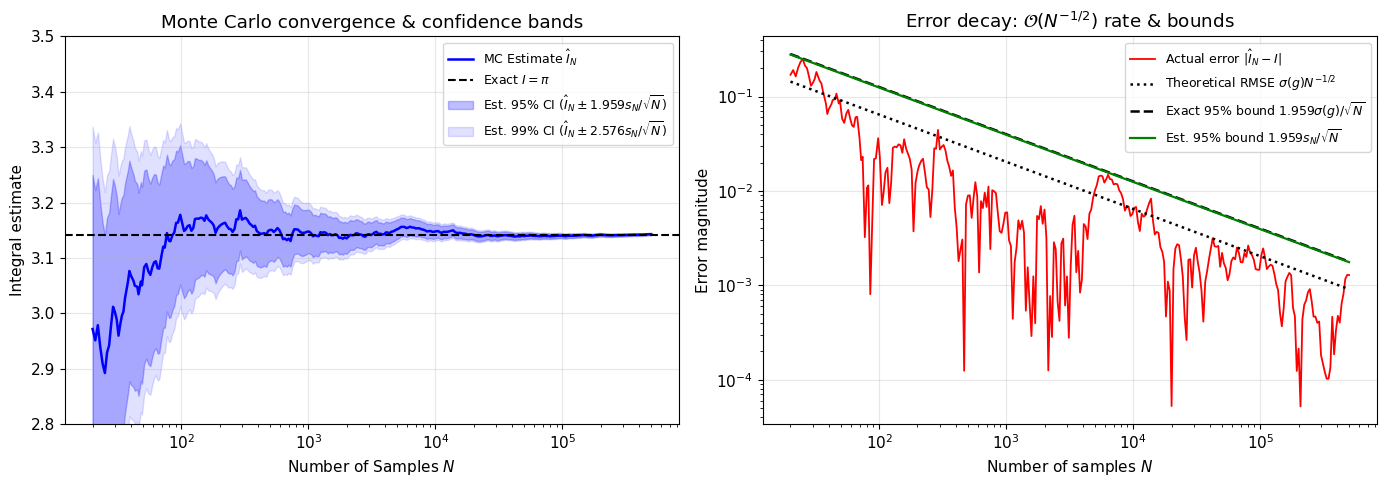

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Running estimate with probabilistic confidence bands
ax = axes[0]
ax.plot(N_grid, I_hat_curve, color="blue",  lw=1.8, label=r"MC Estimate $\hat{I}_N$")
ax.axhline(I_ex, ls="--",    color="black", lw=1.5, label=r"Exact $I = \pi$")
ax.fill_between(
    N_grid,
    I_hat_curve - C_95*s_N_curve/np.sqrt(N_grid),
    I_hat_curve + C_95*s_N_curve/np.sqrt(N_grid),
    color="blue", alpha=0.25, label=r"Est. 95% CI ($\hat{I}_N \pm 1.959 s_N/\sqrt{N}$)"
)
ax.fill_between(
    N_grid,
    I_hat_curve - C_99*s_N_curve/np.sqrt(N_grid),
    I_hat_curve + C_99*s_N_curve/np.sqrt(N_grid),
    color="blue", alpha=0.12, label=r"Est. 99% CI ($\hat{I}_N \pm 2.576 s_N/\sqrt{N}$)"
)
ax.set_xscale("log")
ax.set_ylim(2.8, 3.5)
ax.set_xlabel("Number of Samples $N$")
ax.set_ylabel("Integral estimate")
ax.set_title("Monte Carlo convergence & confidence bands")
ax.legend(loc="upper right", fontsize=9)

# Right panel: Log-log error comparison against exact and estimated bounds
ax = axes[1]
abs_err_curve = np.abs(I_hat_curve - I_ex)
ax.loglog(N_grid, abs_err_curve,                  "r-",  lw=1.3, label=r"Actual error $|\hat{I}_N - I|$")
ax.loglog(N_grid,       sigma_ex/np.sqrt(N_grid), "k:",  lw=1.8, label=r"Theoretical RMSE $\sigma(g)N^{-1/2}$")
ax.loglog(N_grid,  C_95*sigma_ex/np.sqrt(N_grid), "k--", lw=1.8, label=r"Exact 95% bound $1.959 \sigma(g)/\sqrt{N}$")
ax.loglog(N_grid, C_95*s_N_curve/np.sqrt(N_grid), "g-",  lw=1.6, label=r"Est. 95% bound $1.959 s_N/\sqrt{N}$")
ax.set_xlabel("Number of samples $N$")
ax.set_ylabel("Error magnitude")
ax.set_title(r"Error decay: $\mathcal{O}(N^{-1/2})$ rate & bounds")
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()


Store these results for later:

In [132]:
summary_1d = summarize_mc("1D: Uniform(0, 1)", I_ex, I_quad, g_x, sigma_ex)

## 3. Multidimensional Integration on a Circular Region ($d = 2$)

Now consider a 2D integral over a circular disk $D_R = \{ \boldsymbol{x} = (x_1, x_2) \in \mathbb{R}^2 : x_1^2 + x_2^2 \le R^2 \}$ of radius $R = 2$:
$$I = \iint_{D_R} e^{-(x_1^2 + x_2^2)} \, dx_1 \, dx_2.$$

### Exact Analytical Result
Switching to polar coordinates ($x_1 = r\cos\theta$, $x_2 = r\sin\theta$, $dx_1\,dx_2 = r\,dr\,d\theta$):
$$I = \int_{0}^{2\pi} \int_{0}^{R} e^{-r^2} r \, dr \, d\theta = 2\pi \left[ -\frac{1}{2} e^{-r^2} \right]_{0}^{R} = \pi \left(1 - e^{-R^2}\right).$$
For $R = 2$, $I = \pi(1 - e^{-4}) \approx 3.08405238$.

### Two Monte Carlo Formulations on a Circular Region

To cast this integral into the form $I = \int_{\mathbb{R}^2} g(\boldsymbol{x}) f_{\boldsymbol{X}}(\boldsymbol{x}) \, d\boldsymbol{x}$, we compare two natural choices for $f_{\boldsymbol{X}}(\boldsymbol{x})$:

1. **Method A — Bounding-Box (Indicator) Sampling**:
   Sample $\boldsymbol{X} \sim \text{Uniform}([-R, R]^2)$ with area $A_{\text{box}} = (2R)^2$ and PDF $f_{\boldsymbol{X}}(\boldsymbol{x}) = \frac{1}{4R^2}$ on $[-R, R]^2$. Define:
   $$g_{\text{box}}(\boldsymbol{x}) = 4R^2 \, e^{-(x_1^2 + x_2^2)} \, \mathbf{1}_{\{x_1^2 + x_2^2 \le R^2\}}(\boldsymbol{x}).$$

2. **Method B — Direct Uniform Sampling on the Disk $D_R$**:
   Sample $\boldsymbol{X} \sim \text{Uniform}(D_R)$ directly via **inverse transform sampling** in polar coordinates:
   $$r = R\sqrt{U_1}, \quad \theta = 2\pi U_2 \qquad (U_1, U_2 \stackrel{\text{i.i.d.}}{\sim} \text{Uniform}(0, 1)),$$
   yielding $\boldsymbol{x} = (r\cos\theta, r\sin\theta)$ with uniform disk PDF $f_{\boldsymbol{X}}(\boldsymbol{x}) = \frac{1}{\pi R^2}$ on $D_R$. Define:
   $$g_{\text{disk}}(\boldsymbol{x}) = \pi R^2 \, e^{-(x_1^2 + x_2^2)}.$$

Notice that **both** estimators are unbiased ($\mathbb{E}[g_{\text{box}}(\boldsymbol{X})] = \mathbb{E}[g_{\text{disk}}(\boldsymbol{X})] = I$), but direct disk sampling avoids wasting samples outside $D_R$ and therefore achieves a strictly smaller variance $\sigma^2(g)$.


In [133]:
R = 2.0
area_box = (2.0*R) ** 2
area_disk = np.pi*R ** 2

# Exact analytical integral
I_2d_exact = np.pi*(1.0 - np.exp(-R**2))

# Exact numerical quadrature via scipy.integrate.dblquad
I_2d_dblquad, dblquad_err = integrate.dblquad(
    lambda x1, x2: np.exp(-(x1**2 + x2**2)),
    -R, R,
    lambda x2: -np.sqrt(max(0.0, R**2 - x2**2)),
    lambda x2:  np.sqrt(max(0.0, R**2 - x2**2))
)

# Exact analytical variances sigma^2(g) for both methods
# Note: int_{D_R} exp(-2 r^2) dA = (pi/2)*(1 - exp(-2 R^2))
int_sq_integrand = 0.5*np.pi*(1.0 - np.exp(-2.0*R**2))

# Method A: E[g_box^2] = area_box*int_sq_integrand
sigma_2d_box_exact = np.sqrt(area_box*int_sq_integrand - I_2d_exact**2)

# Method B: E[g_disk^2] = area_disk*int_sq_integrand
sigma_2d_disk_exact = np.sqrt(area_disk*int_sq_integrand - I_2d_exact**2)

print(f"Exact analytical integral I             : {I_2d_exact:.10f}")
print(f"Numerical quadrature (dblquad)          : {I_2d_dblquad:.10f} (abs err = {dblquad_err:.2e})")
print(f"Exact sigma(g) — Bounding Box (Method A): {sigma_2d_box_exact:.6f}")
print(f"Exact sigma(g) — Direct Disk  (Method B): {sigma_2d_disk_exact:.6f}")
print(f"Variance reduction factor (A/B)       : {(sigma_2d_box_exact/sigma_2d_disk_exact)**2:.2f}x")


Exact analytical integral I             : 3.0840523770
Numerical quadrature (dblquad)          : 3.0840523770 (abs err = 1.44e-08)
Exact sigma(g) — Bounding Box (Method A): 3.951320
Exact sigma(g) — Direct Disk  (Method B): 3.197062
Variance reduction factor (A/B)       : 1.53x


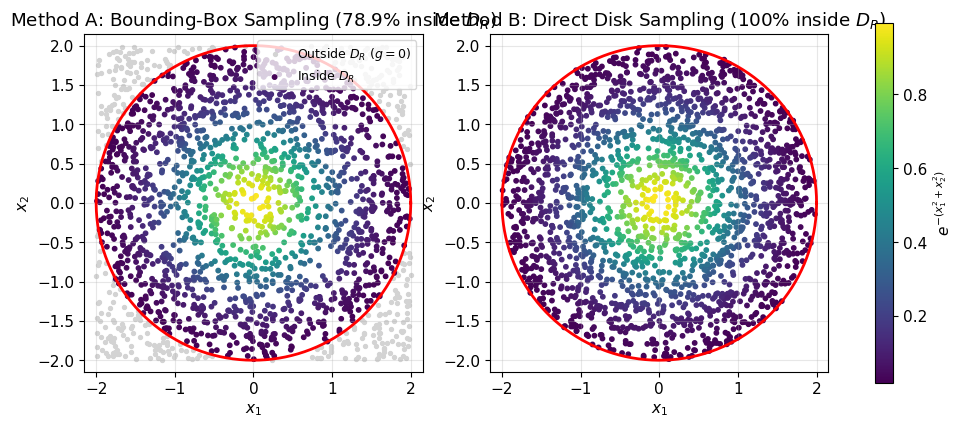

In [134]:
# Visualize the two sampling geometries on the circular region (N_vis = 2,000 samples)
N_vis = 2_000

# Method A samples
x_box_vis = rng.uniform(-R, R, size=(N_vis, 2))
r2_box_vis = np.sum(x_box_vis**2, axis=1)
inside = r2_box_vis <= R**2

# Method B samples (inverse transform sampling on disk)
u1 = rng.uniform(0.0, 1.0, size=N_vis)
u2 = rng.uniform(0.0, 1.0, size=N_vis)
r_disk_vis = R*np.sqrt(u1)
theta_disk_vis = 2.0*np.pi*u2
x_disk_vis = np.column_stack([r_disk_vis*np.cos(theta_disk_vis),
                              r_disk_vis*np.sin(theta_disk_vis)])
vals_disk_vis = np.exp(-(x_disk_vis[:, 0]**2 + x_disk_vis[:, 1]**2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
circle_theta = np.linspace(0, 2*np.pi, 300)

# Plot Method A
ax = axes[0]
ax.scatter(x_box_vis[~inside, 0], x_box_vis[~inside, 1], s=8, color="lightgray", label="Outside $D_R$ ($g=0$)")
sc1 = ax.scatter(x_box_vis[inside, 0], x_box_vis[inside, 1], s=10,
                 c=np.exp(-r2_box_vis[inside]), cmap="viridis", label="Inside $D_R$")
ax.plot(R*np.cos(circle_theta), R*np.sin(circle_theta), "r-", lw=2)
ax.set_aspect("equal")
ax.set_xlim(-R - 0.15, R + 0.15)
ax.set_ylim(-R - 0.15, R + 0.15)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title(f"Method A: Bounding-Box Sampling ({inside.mean()*100:.1f}% inside $D_R$)")
ax.legend(loc="upper right", fontsize=9)

# Plot Method B
ax = axes[1]
sc2 = ax.scatter(x_disk_vis[:, 0], x_disk_vis[:, 1], s=10, c=vals_disk_vis, cmap="viridis")
ax.plot(R*np.cos(circle_theta), R*np.sin(circle_theta), "r-", lw=2)
ax.set_aspect("equal")
ax.set_xlim(-R - 0.15, R + 0.15)
ax.set_ylim(-R - 0.15, R + 0.15)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Method B: Direct Disk Sampling (100% inside $D_R$)")
cbar = fig.colorbar(sc2, ax=axes.ravel().tolist(), shrink=0.85, label=r"$e^{-(x_1^2 + x_2^2)}$")

plt.show()


In [135]:
# Run 2D Monte Carlo integration for both methods up to N_max = 500,000
N_max_2d = 500_000

# Method A: Bounding-Box
x_box = rng.uniform(-R, R, size=(N_max_2d, 2))
r2_box = np.sum(x_box**2, axis=1)
g_box_vals = np.where(r2_box <= R**2, area_box*np.exp(-r2_box), 0.0)

# Method B: Direct Disk
u1 = rng.uniform(0.0, 1.0, size=N_max_2d)
u2 = rng.uniform(0.0, 1.0, size=N_max_2d)
r_disk = R*np.sqrt(u1)
theta_disk = 2.0*np.pi*u2
x_disk = np.column_stack([r_disk*np.cos(theta_disk), r_disk*np.sin(theta_disk)])
g_disk_vals = area_disk*np.exp(-(x_disk[:, 0]**2 + x_disk[:, 1]**2))

# Build comparison table across sample sizes N
rows_2d = []
for N in sample_sizes:
    hat_a = np.mean(g_box_vals[:N])
    s_a = np.std(g_box_vals[:N], ddof=1)
    err_a = np.abs(hat_a - I_2d_exact)

    hat_b = np.mean(g_disk_vals[:N])
    s_b = np.std(g_disk_vals[:N], ddof=1)
    err_b = np.abs(hat_b - I_2d_exact)

    rows_2d.append({
        "N": N,
        "Exact I": I_2d_exact,
        "Box I_hat": hat_a,
        "Box |Err|": err_a,
        "Box Est. 95%": C_95*s_a/np.sqrt(N),
        "Disk I_hat": hat_b,
        "Disk |Err|": err_b,
        "Disk Est. 95%": C_95*s_b/np.sqrt(N),
    })

df_2d = pd.DataFrame(rows_2d)
display(df_2d.style.format({
    "N": "{:,}",
    "Exact I": "{:.6f}",
    "Box I_hat": "{:.6f}",
    "Box |Err|": "{:.6f}",
    "Box Est. 95%": "{:.6f}",
    "Disk I_hat": "{:.6f}",
    "Disk |Err|": "{:.6f}",
    "Disk Est. 95%": "{:.6f}",
}))


,N,Exact I,Box I_hat,Box |Err|,Box Est. 95%,Disk I_hat,Disk |Err|,Disk Est. 95%
0,10,3.084052,3.894559,0.810507,2.730864,4.075219,0.991166,2.705643
1,50,3.084052,3.960625,0.876573,1.281251,2.855135,0.228918,0.888182
2,100,3.084052,3.620423,0.536371,0.813215,3.169751,0.085699,0.688910
3,500,3.084052,3.169019,0.084966,0.331581,3.260163,0.176111,0.293615
4,"1,000",3.084052,3.234121,0.150068,0.243253,3.198899,0.114847,0.206833
5,"5,000",3.084052,3.067107,0.016946,0.107779,3.051231,0.032821,0.087769
6,"10,000",3.084052,3.124020,0.039967,0.077874,3.087313,0.003261,0.062672
7,"50,000",3.084052,3.126908,0.042856,0.034897,3.087883,0.003831,0.028006
8,"100,000",3.084052,3.104299,0.020246,0.024578,3.085942,0.001890,0.019780
9,"500,000",3.084052,3.088839,0.004787,0.010961,3.086503,0.002450,0.008860


## 4. Probabilistic Error Bounds as $N$ Increases: Exact vs. Estimated

In real applications, the true variance $\sigma^2(g)$ is unknown and must be replaced by the unbiased sample variance $s_N^2$. Here we examine two crucial aspects for the 2D circular-region integral:

1. **Convergence of $s_N \to \sigma(g)$ and Bound Accuracy**: How closely does the computable bound $c \, s_N/\sqrt{N}$ track the exact theoretical bound $c \, \sigma(g)/\sqrt{N}$ as $N$ grows?
2. **Empirical CLT Validation (Repeated Trials)**: By running $M = 1{,}000$ independent Monte Carlo simulations at a fixed $N$, we verify that:
   - The standardized error $Z_N = \frac{\sqrt{N}(\hat{I}_N - I)}{\sigma(g)}$ converges to the standard normal distribution $\mathcal{N}(0, 1)$.
   - The empirical fraction of trials satisfying $|\hat{I}_N - I| \le c \, s_N/\sqrt{N}$ matches the theoretical confidence levels ($95\%$ for $c = 1.96$ and $99\%$ for $c = 2.576$).


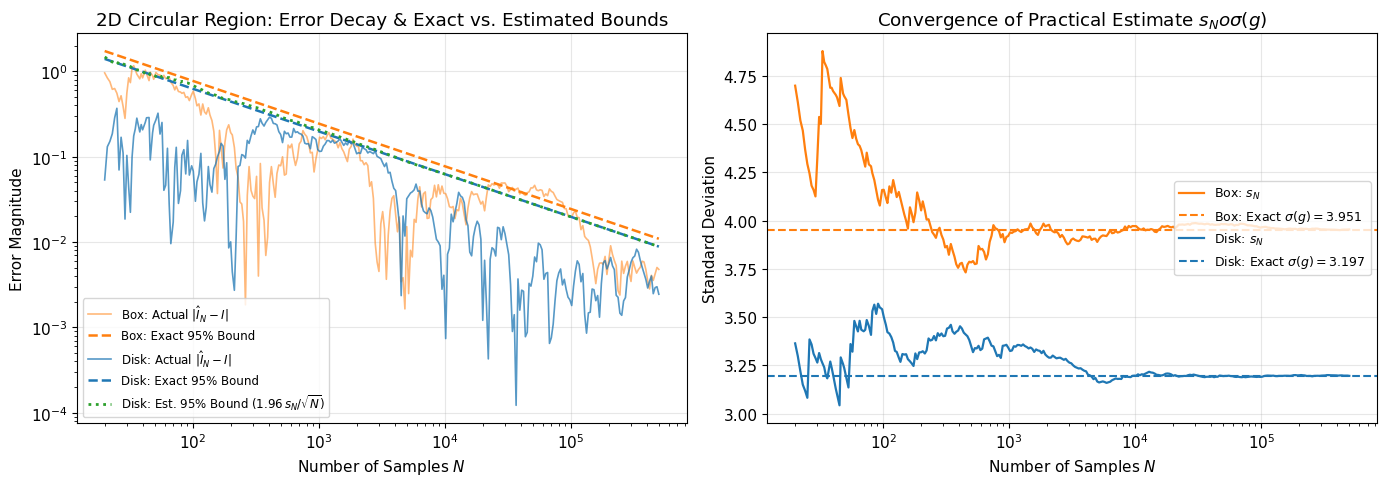

In [136]:
# Compare running error and exact vs estimated 95% bounds for both 2D methods
N_grid_2d = np.unique(np.geomspace(20, N_max_2d, 300).astype(int))

def running_stats(vals, idx):
    cs = np.cumsum(vals)[idx - 1]
    cs2 = np.cumsum(vals**2)[idx - 1]
    mean = cs/idx
    var = (cs2 - idx*mean**2)/(idx - 1)
    return mean, np.sqrt(np.maximum(var, 0.0))

hat_box_c, s_box_c = running_stats(g_box_vals, N_grid_2d)
hat_disk_c, s_disk_c = running_stats(g_disk_vals, N_grid_2d)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Log-log error & bounds for Direct Disk (Method B) vs Bounding Box (Method A)
ax = axes[0]
ax.loglog(N_grid_2d, np.abs(hat_box_c - I_2d_exact), color="#ff7f0e", alpha=0.55, lw=1.2, label=r"Box: Actual $|\hat{I}_N - I|$")
ax.loglog(N_grid_2d, C_95*sigma_2d_box_exact/np.sqrt(N_grid_2d), color="#ff7f0e", ls="--", lw=1.8, label=r"Box: Exact 95% Bound")
ax.loglog(N_grid_2d, np.abs(hat_disk_c - I_2d_exact), color="#1f77b4", alpha=0.75, lw=1.2, label=r"Disk: Actual $|\hat{I}_N - I|$")
ax.loglog(N_grid_2d, C_95*sigma_2d_disk_exact/np.sqrt(N_grid_2d), color="#1f77b4", ls="--", lw=1.8, label=r"Disk: Exact 95% Bound")
ax.loglog(N_grid_2d, C_95*s_disk_c/np.sqrt(N_grid_2d), color="#2ca02c", ls=":", lw=2.0, label=r"Disk: Est. 95% Bound ($1.96\,s_N/\sqrt{N}$)")
ax.set_xlabel("Number of Samples $N$")
ax.set_ylabel("Error Magnitude")
ax.set_title("2D Circular Region: Error Decay & Exact vs. Estimated Bounds")
ax.legend(loc="lower left", fontsize=8.5)

# Right: Convergence of sample standard deviation s_N to exact sigma(g)
ax = axes[1]
ax.semilogx(N_grid_2d, s_box_c, color="#ff7f0e", lw=1.6, label=r"Box: $s_N$")
ax.axhline(sigma_2d_box_exact, color="#ff7f0e", ls="--", lw=1.5, label=rf"Box: Exact $\sigma(g) = {sigma_2d_box_exact:.3f}$")
ax.semilogx(N_grid_2d, s_disk_c, color="#1f77b4", lw=1.6, label=r"Disk: $s_N$")
ax.axhline(sigma_2d_disk_exact, color="#1f77b4", ls="--", lw=1.5, label=rf"Disk: Exact $\sigma(g) = {sigma_2d_disk_exact:.3f}$")
ax.set_xlabel("Number of Samples $N$")
ax.set_ylabel("Standard Deviation")
ax.set_title(r"Convergence of Practical Estimate $s_N 	o \sigma(g)$")
ax.legend(loc="right", fontsize=9)

plt.tight_layout()
plt.show()


,Metric,Theoretical,"Empirical (M=1,000 trials)"
0,RMSE (Average Error),0.045213,0.044066
1,95% Bound Coverage (Exact sigma),95.0%,95.8%
2,95% Bound Coverage (Estimated s_N),95.0%,95.8%
3,99% Bound Coverage (Exact sigma),99.0%,99.2%
4,99% Bound Coverage (Estimated s_N),99.0%,99.1%


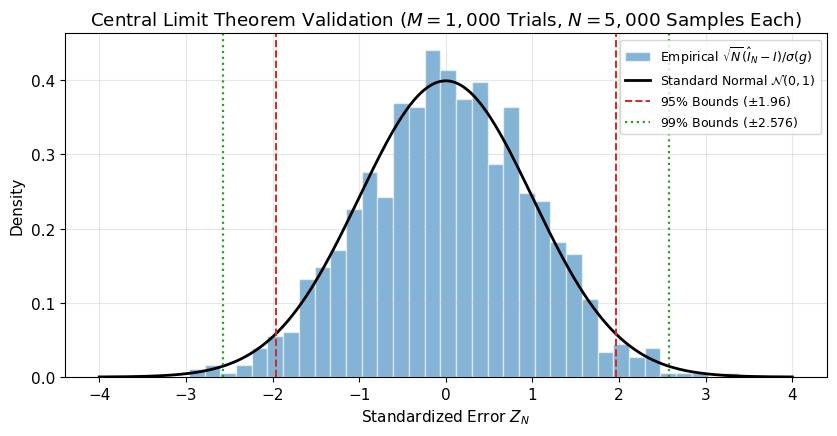

In [137]:
# Empirical CLT Validation: M = 1,000 independent trials at N = 5,000 (Direct Disk Method)
M_trials = 1_000
N_trial = 5_000

u1_trials = rng.uniform(0.0, 1.0, size=(M_trials, N_trial))
g_trials = area_disk*np.exp(-(R**2)*u1_trials)

I_hats = np.mean(g_trials, axis=1)
s_Ns = np.std(g_trials, axis=1, ddof=1)
errors = I_hats - I_2d_exact

# Empirical coverage using EXACT sigma(g) vs ESTIMATED s_N
cov_95_exact = np.mean(np.abs(errors) <= C_95*sigma_2d_disk_exact/np.sqrt(N_trial))
cov_95_est   = np.mean(np.abs(errors) <= C_95*s_Ns/np.sqrt(N_trial))
cov_99_exact = np.mean(np.abs(errors) <= C_99*sigma_2d_disk_exact/np.sqrt(N_trial))
cov_99_est   = np.mean(np.abs(errors) <= C_99*s_Ns/np.sqrt(N_trial))

# Empirical RMSE vs theoretical RMSE
emp_rmse = np.sqrt(np.mean(errors**2))
theo_rmse = sigma_2d_disk_exact/np.sqrt(N_trial)

clt_summary = pd.DataFrame({
    "Metric": [
        "RMSE (Average Error)",
        "95% Bound Coverage (Exact sigma)",
        "95% Bound Coverage (Estimated s_N)",
        "99% Bound Coverage (Exact sigma)",
        "99% Bound Coverage (Estimated s_N)",
    ],
    "Theoretical": [
        f"{theo_rmse:.6f}",
        "95.0%",
        "95.0%",
        "99.0%",
        "99.0%",
    ],
    "Empirical (M=1,000 trials)": [
        f"{emp_rmse:.6f}",
        f"{cov_95_exact*100:.1f}%",
        f"{cov_95_est*100:.1f}%",
        f"{cov_99_exact*100:.1f}%",
        f"{cov_99_est*100:.1f}%",
    ]
})
display(clt_summary)

# Histogram of standardized errors vs standard normal N(0, 1)
z_scores = np.sqrt(N_trial)*errors/sigma_2d_disk_exact
z_grid = np.linspace(-4, 4, 300)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(z_scores, bins=35, density=True, color="#1f77b4", alpha=0.55, edgecolor="white",
        label=r"Empirical $\sqrt{N}(\hat{I}_N - I)/\sigma(g)$")
ax.plot(z_grid, stats.norm.pdf(z_grid), "k-", lw=2, label=r"Standard Normal $\mathcal{N}(0, 1)$")
ax.axvline(-C_95, color="#d62728", ls="--", lw=1.4, label=r"95% Bounds ($\pm 1.96$)")
ax.axvline(C_95, color="#d62728", ls="--", lw=1.4)
ax.axvline(-C_99, color="#2ca02c", ls=":", lw=1.6, label=r"99% Bounds ($\pm 2.576$)")
ax.axvline(C_99, color="#2ca02c", ls=":", lw=1.6)
ax.set_xlabel("Standardized Error $Z_N$")
ax.set_ylabel("Density")
ax.set_title(f"Central Limit Theorem Validation ($M={M_trials:,}$ Trials, $N={N_trial:,}$ Samples Each)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


---
## 5. Final Comparison: Exact vs. Numerical Quadrature vs. Monte Carlo Estimates

Let's assemble a consolidated summary table at $N = 500{,}000$ comparing all methods side by side.


In [138]:
summary_df = pd.DataFrame([
    summary_1d,
    summarize_mc("2D Disk: Bounding-Box (Method A)", I_2d_exact, I_2d_dblquad, g_box_vals, sigma_2d_box_exact),
    summarize_mc("2D Disk: Direct Disk (Method B)", I_2d_exact, I_2d_dblquad, g_disk_vals, sigma_2d_disk_exact),
])

display(summary_df.style.format({
    "Exact Analytical I": "{:.6f}",
    "SciPy Quadrature": "{:.6f}",
    f"MC Estimate (N={final_N:,})": "{:.6f}",
    "Abs Error |I_hat - I|": "{:.6f}",
    "Rel Error (%)": "{:.4f}%",
    "Exact 95% Bound": "{:.6f}",
    "Est. 95% Bound": "{:.6f}",
}))


,Problem/Method,Exact Analytical I,SciPy Quadrature,"MC Estimate (N=500,000)",Abs Error |I_hat - I|,Rel Error (%),Exact 95% Bound,Est. 95% Bound,Exact I in Est. 95% CI?
0,"1D: Uniform(0, 1)",3.141593,3.141593,3.142877,0.001285,0.0409%,0.001783,0.001782,True
1,2D Disk: Bounding-Box (Method A),3.084052,3.084052,3.088839,0.004787,0.1552%,0.010952,0.010961,True
2,2D Disk: Direct Disk (Method B),3.084052,3.084052,3.086503,0.002450,0.0795%,0.008862,0.008860,True
